<a href="https://colab.research.google.com/github/Cintya-rdev/ml-primeiro-modelo/blob/main/2026-11-14-v0.2-pipeline_bioh2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Importação das Bibliotecas



In [82]:
# BLOCO 1: Importação das bibliotecas essenciais da Fase 1
import pandas as pd   # Manipulação de tabelas (DataFrames)
import numpy as np    # Operações matemáticas e geração de números

print("Ambiente Python do Colab pronto! Versão do Pandas:", pd.__version__)

Ambiente Python do Colab pronto! Versão do Pandas: 2.2.3


2. Geração do Dataset Provisório em Batelada (250 ensaios)

In [83]:
# BLOCO 2: Geração do Dataset Provisório em Batelada (250 ensaios)
np.random.seed(42) # Trava a semente aleatória para dar sempre os mesmos números
n = 250            # Número de frascos/ensaios simulados

# Criando a tabela (DataFrame) com as 11 variáveis pré-aprovadas (X01 a X11)
df_bruto = pd.DataFrame({
    # 3 Variáveis Categóricas (Texto)
    'x01_substrato': np.random.choice(['vinhaca', 'glicerol', 'lignocelulosico', 'efluentes'], n),
    'x02_origem_inoculo': np.random.choice(['lodo_uasb', 'lodo_ete', 'ruminal', 'consorcio_misto'], n),
    'x11_pre_tratamento': np.random.choice(['nenhum', 'termico', 'acido', 'alcalino'], n),

    # 8 Variáveis Numéricas Contínuas (Números)
    'x03_art_g_l': np.random.uniform(5.0, 40.0, n),               # Açúcares Redutores Totais (g/L)
    'x04_relacao_inoculo_substrato': np.random.uniform(0.5, 3.0, n), # g SV / g DQO
    'x05_conc_inoculo_g_l': np.random.uniform(2.0, 15.0, n),      # Concentração de inóculo (g/L)
    'x06_ph_inicial': np.random.uniform(4.5, 7.5, n),             # pH inicial
    'x07_temperatura_c': np.random.uniform(30.0, 55.0, n),        # Temperatura (°C)
    'x08_tempo_fermentacao_h': np.random.uniform(12.0, 72.0, n),  # Tempo de batelada (h)
    'x09_volume_reator_l': np.random.choice([0.1, 0.25, 0.5, 1.0], n), # Volume do frasco (L)
    'x10_volume_headspace_l': np.random.choice([0.05, 0.1, 0.2, 0.4], n) # Headspace (L)
})

# Simulando o Alvo (y): Rendimento de H2 (mL/g) com ótimo biológico perto de pH 5.8 e 37°C
efeito_ph = -8.0 * (df_bruto['x06_ph_inicial'] - 5.8)**2
efeito_temp = -0.15 * (df_bruto['x07_temperatura_c'] - 37.0)**2
ruido = np.random.normal(0, 3.0, n)

df_bruto['y_rendimento_h2_ml_g'] = (
    45.0
    + 0.6 * df_bruto['x03_art_g_l']
    + 4.0 * df_bruto['x04_relacao_inoculo_substrato']
    + efeito_ph
    + efeito_temp
    + ruido
).clip(lower=5.0) # Garante que não exista rendimento negativo

# Inserindo 10 falhas de medição APENAS em análises laboratoriais de bancada (ART e Sólidos do Inóculo)
indices_nulos = np.random.choice(df_bruto.index, size=10, replace=False)
df_bruto.loc[indices_nulos[:5], 'x03_art_g_l'] = np.nan
df_bruto.loc[indices_nulos[5:], 'x05_conc_inoculo_g_l'] = np.nan

df_bruto.head() # Visualizando as 5 primeiras linhas da nossa tabela




,x01_substrato,x02_origem_inoculo,x11_pre_tratamento,x03_art_g_l,x04_relacao_inoculo_substrato,x05_conc_inoculo_g_l,x06_ph_inicial,x07_temperatura_c,x08_tempo_fermentacao_h,x09_volume_reator_l,x10_volume_headspace_l,y_rendimento_h2_ml_g
0,lignocelulosico,lodo_ete,acido,16.164147,1.422284,4.029984,6.152572,51.768748,53.400293,0.5,0.4,30.121983
1,efluentes,lodo_uasb,nenhum,34.570636,1.656337,11.307639,4.760960,41.132631,24.056021,0.1,0.2,65.466130
2,vinhaca,consorcio_misto,nenhum,5.814518,2.368677,10.566011,5.725360,42.870434,44.149661,0.1,0.2,49.182518
3,lignocelulosico,lodo_uasb,alcalino,33.506397,0.591708,2.352248,5.618066,38.980834,17.800587,0.1,0.2,65.851558
4,lignocelulosico,lodo_uasb,acido,14.864917,1.131092,4.885638,5.279261,44.823771,39.022256,1.0,0.4,47.190434


3. Análise Exploratória dos Dados (EDA)

In [84]:
# BLOCO 3: Análise Exploratória dos Dados (EDA)

# 1. Verificar dimensões (linhas, colunas)
print(f"Dimensões do Dataset: {df_bruto.shape[0]} ensaios (linhas) e {df_bruto.shape[1]} colunas.\n")

# 2. Contar quantos valores ausentes (NaN) existem em cada coluna
print("--- Contagem de Valores Ausentes (Nulos) por Variável ---")
print(df_bruto.isnull().sum())
print("\n" + "="*60 + "\n")

# 3. Estatísticas descritivas das variáveis numéricas (arredondado para 2 casas decimais)
print("--- Resumo Estatístico das Variáveis Numéricas ---")
display(df_bruto.describe().round(2))

Dimensões do Dataset: 250 ensaios (linhas) e 12 colunas.

--- Contagem de Valores Ausentes (Nulos) por Variável ---
x01_substrato                    0
x02_origem_inoculo               0
x11_pre_tratamento               0
x03_art_g_l                      5
x04_relacao_inoculo_substrato    0
x05_conc_inoculo_g_l             5
x06_ph_inicial                   0
x07_temperatura_c                0
x08_tempo_fermentacao_h          0
x09_volume_reator_l              0
x10_volume_headspace_l           0
y_rendimento_h2_ml_g             0
dtype: int64


--- Resumo Estatístico das Variáveis Numéricas ---


,x03_art_g_l,x04_relacao_inoculo_substrato,x05_conc_inoculo_g_l,x06_ph_inicial,x07_temperatura_c,x08_tempo_fermentacao_h,x09_volume_reator_l,x10_volume_headspace_l,y_rendimento_h2_ml_g
count,245.00,250.00,245.00,250.00,250.00,250.00,250.00,250.00,250.00
mean,23.13,1.71,8.50,6.03,42.42,42.32,0.47,0.20,47.15
std,10.72,0.70,3.91,0.88,7.10,17.83,0.35,0.14,16.66
min,5.38,0.51,2.14,4.52,30.12,12.66,0.10,0.05,5.00
25%,13.66,1.11,5.01,5.23,36.12,26.15,0.25,0.10,37.51
50%,23.31,1.67,8.66,6.12,42.88,42.47,0.25,0.20,49.87
75%,33.12,2.32,12.02,6.77,47.71,58.16,1.00,0.40,59.09
max,39.99,2.99,14.93,7.49,54.99,71.80,1.00,0.40,80.36


4.
Separação X / y e Divisão Holdout (80% Treino / 20% Teste)

In [85]:
#r BLOCO 4 (v0.2): Carregando o arquivo direto da raiz (/dataset_sintetico_v02.csv) + Divisão Holdout
import os
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# 1. Lê o CSV (seja na raiz '/' onde você subiu ou em '/content/')
if os.path.exists('/dataset_sintetico_v02.csv'):
    df_v02 = pd.read_csv('/dataset_sintetico_v02.csv')
else:
    df_v02 = pd.read_csv('dataset_sintetico_v02.csv')

# 2. Definir exatamente as 7 features (3 categóricas + 4 numéricas):
colunas_categoricas = [
    'tipo_substrato',
    'origem_inoculo',
    'tipo_pretratamento'
]

colunas_numericas = [
    'conc_substrato_gsv_l',
    'relacao_i_s',
    'ph_inicial',
    'temperatura_c'
]

coluna_alvo  = 'y04_ml_h2_por_g_sv'
coluna_grupo = 'id_condicao'

# 3. Separar X, y e grupos
X = df_v02[colunas_categoricas + colunas_numericas]
y = df_v02[coluna_alvo]
grupos = df_v02[coluna_grupo]

# 4. Divisão Holdout 80/20 respeitando as triplicatas
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
idx_treino, idx_teste = next(gss.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_treino], X.iloc[idx_teste]
y_train, y_test = y.iloc[idx_treino], y.iloc[idx_teste]

print(f"Sucesso! Total de linhas carregadas: {len(df_v02)}")
print(f"Treino (80%): {len(X_train)} ensaios ({grupos.iloc[idx_treino].nunique()} condições em triplicata)")
print(f"Teste  (20%): {len(X_test)} ensaios ({grupos.iloc[idx_teste].nunique()} condições em triplicata)")

Sucesso! Total de linhas carregadas: 1200
Treino (80%): 960 ensaios (320 condições em triplicata)
Teste  (20%): 240 ensaios (80 condições em triplicata)


5. Pré-processamento sem Vazamento de Dados (ColumnTransformer)


In [86]:
# BLOCO 5 (v0.2): Atualizando o ColumnTransformer com as 7 colunas novas
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Confirma os nomes exatos das 7 colunas do dataset v0.2
colunas_categoricas = [
    'tipo_substrato',
    'origem_inoculo',
    'tipo_pretratamento'
]

colunas_numericas = [
    'conc_substrato_gsv_l',
    'relacao_i_s',
    'ph_inicial',
    'temperatura_c'
]

# 2. Regras para numéricas e categóricas
regra_numerica = Pipeline(steps=[
    ('imputador_mediana', SimpleImputer(strategy='median')),
    ('escalonador_padrao', StandardScaler())
])

regra_categorica = Pipeline(steps=[
    ('codificador_onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 3. Atualiza o objeto 'preprocessador' com as colunas novas!
preprocessador = ColumnTransformer(transformers=[
    ('num', regra_numerica, colunas_numericas),
    ('cat', regra_categorica, colunas_categoricas)
])

preprocessador

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputador_mediana',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalonador_padrao',
                                                  StandardScaler())]),
                                 ['conc_substrato_gsv_l', 'relacao_i_s',
                                  'ph_inicial', 'temperatura_c']),
                                ('cat',
                                 Pipeline(steps=[('codificador_onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['tipo_substrato', 'origem_inoculo',
                                  'tipo_pretratamento'])])

6: Modelo na Pipeline e Treinanamento

In [87]:
# BLOCO 6: Acoplamento Modelo + Preprocessador e Treinamento
from sklearn.ensemble import RandomForestRegressor

# 1. Criar a Pipeline Completa (Preprocessador + Algoritmo)
pipeline_v01 = Pipeline(steps=[
    ('preprocessamento', preprocessador),
    ('modelo_rf', RandomForestRegressor(n_estimators=100, random_state=42))
])

# 2. Treinar a pipeline APENAS com os 200 ensaios de treino (80%)
# Aqui ela aprende a mediana, a escala, as categorias e treina as 100 árvores!
pipeline_v01.fit(X_train, y_train)

# 3. Fazer a previsão cega nos 50 ensaios de teste (20%) que estavam trancados
y_pred = pipeline_v01.predict(X_test)

# Mostrar uma comparação rápida dos 5 primeiros ensaios do teste (Real vs. Previsto)
comparacao = pd.DataFrame({
    'Y_Real (mL/g)': y_test.values[:5].round(2),
    'Y_Predito (mL/g)': y_pred[:5].round(2),
    'Erro / Resíduo (mL/g)': (y_test.values[:5] - y_pred[:5]).round(2)
})
display(comparacao)

,Y_Real (mL/g),Y_Predito (mL/g),Erro / Resíduo (mL/g)
0,314.7,284.52,30.18
1,363.4,284.52,78.88
2,97.6,284.52,-186.92
3,8.6,7.49,1.11
4,3.9,7.49,-3.59


7. Avaliação de Desempenho, Gráficos e Salvamento

=== DESEMPENHO DA PIPELINE v0.2 (1.200 ENSAIOS CALIBRADOS) ===
MAE  (Erro Médio Absoluto):      52.06 mL H2/g SV
RMSE (Raiz do Erro Quadrático):  67.77 mL H2/g SV
R²   (Coeficiente Determinação): 0.6163 (61.6% da variância explicada)



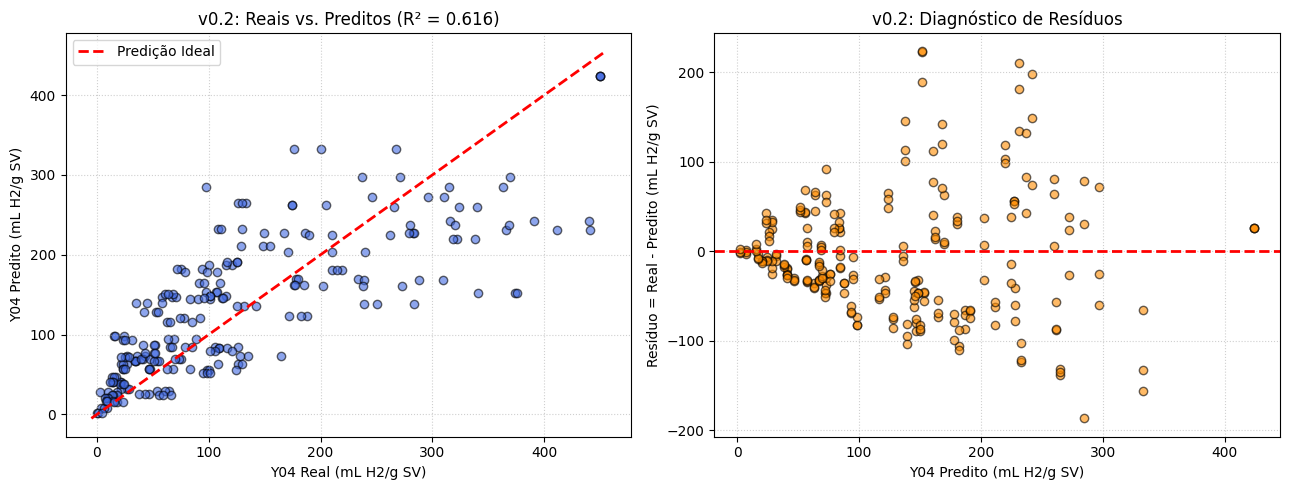

['pipeline_bioh2_v02.joblib']

In [88]:
# BLOCO 7 (v0.2): Avaliação de Desempenho e Diagnóstico de Resíduos
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import matplotlib.pyplot as plt
import joblib

mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== DESEMPENHO DA PIPELINE v0.2 (1.200 ENSAIOS CALIBRADOS) ===")
print(f"MAE  (Erro Médio Absoluto):      {mae:.2f} mL H2/g SV")
print(f"RMSE (Raiz do Erro Quadrático):  {rmse:.2f} mL H2/g SV")
print(f"R²   (Coeficiente Determinação): {r2:.4f} ({r2*100:.1f}% da variância explicada)\n")

residuos = y_test - y_pred
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.scatter(y_test, y_pred, alpha=0.6, edgecolors='k', color='royalblue')
limites = [min(y_test.min(), y_pred.min()) - 5, max(y_test.max(), y_pred.max()) + 5]
ax1.plot(limites, limites, 'r--', lw=2, label='Predição Ideal')
ax1.set_xlabel('Y04 Real (mL H2/g SV)')
ax1.set_ylabel('Y04 Predito (mL H2/g SV)')
ax1.set_title(f'v0.2: Reais vs. Preditos (R² = {r2:.3f})')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.scatter(y_pred, residuos, alpha=0.6, edgecolors='k', color='darkorange')
ax2.axhline(0, color='r', linestyle='--', lw=2)
ax2.set_xlabel('Y04 Predito (mL H2/g SV)')
ax2.set_ylabel('Resíduo = Real - Predito (mL H2/g SV)')
ax2.set_title('v0.2: Diagnóstico de Resíduos')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('diagnostico_v02.png', dpi=300)
plt.show()

joblib.dump(pipeline_v02, 'pipeline_bioh2_v02.joblib')

8. Análise por Condição (Média das Triplicatas) + Importância das Variáveis

=== DIAGNÓSTICO DO ERRO ENTRE TRIPLICATAS ===
1. R² nas réplicas individuais brutas (240 frascos): 0.6163 (MAE = 52.06 mL/g SV)
2. R² na MÉDIA das triplicatas (80 condições):       0.6379 (MAE = 49.68 mL/g SV)
3. R² na MEDIANA das triplicatas (robusto a falhas): 0.6313 (MAE = 50.80 mL/g SV)



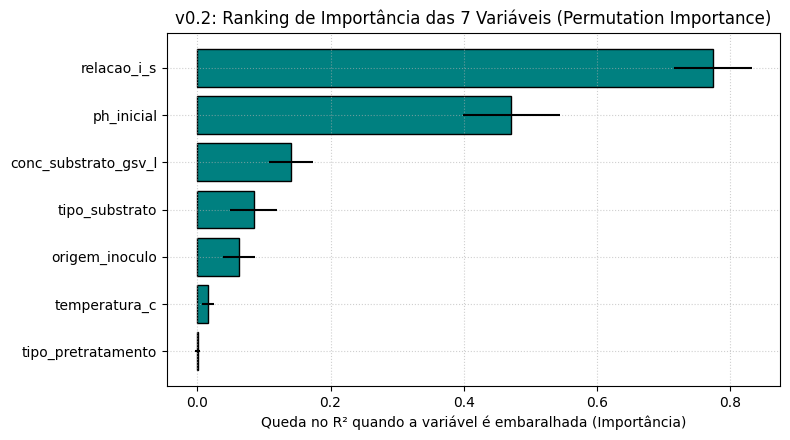

In [89]:
# BLOCO 8 (v0.2 Corrigido): Análise por Triplicata (Média vs Mediana) + Importância das Variáveis
from sklearn.inspection import permutation_importance

# 1. Juntar as previsões do teste com o id_condicao
df_teste_analise = df_v02.iloc[idx_teste].copy()
df_teste_analise['y_pred'] = y_pred

# 2. Avaliar na MÉDIA das 3 réplicas de cada condição
media_triplicatas = df_teste_analise.groupby('id_condicao')[[coluna_alvo, 'y_pred']].mean()
r2_media = r2_score(media_triplicatas[coluna_alvo], media_triplicatas['y_pred'])
mae_media = mean_absolute_error(media_triplicatas[coluna_alvo], media_triplicatas['y_pred'])

# 3. Avaliar na MEDIANA das 3 réplicas (filtra automaticamente se 1 dos 3 frascos vazou!)
mediana_triplicatas = df_teste_analise.groupby('id_condicao')[[coluna_alvo, 'y_pred']].median()
r2_mediana = r2_score(mediana_triplicatas[coluna_alvo], mediana_triplicatas['y_pred'])
mae_mediana = mean_absolute_error(mediana_triplicatas[coluna_alvo], mediana_triplicatas['y_pred'])

print("=== DIAGNÓSTICO DO ERRO ENTRE TRIPLICATAS ===")
print(f"1. R² nas réplicas individuais brutas (240 frascos): {r2:.4f} (MAE = {mae:.2f} mL/g SV)")
print(f"2. R² na MÉDIA das triplicatas (80 condições):       {r2_media:.4f} (MAE = {mae_media:.2f} mL/g SV)")
print(f"3. R² na MEDIANA das triplicatas (robusto a falhas): {r2_mediana:.4f} (MAE = {mae_mediana:.2f} mL/g SV)\n")

# 4. Calcular a Importância das 7 Variáveis (Permutation Importance no Teste)
importancias = permutation_importance(pipeline_v02, X_test, y_test, n_repeats=10, random_state=42)
df_imp = pd.DataFrame({
    'Variavel': X_test.columns,
    'Importancia_Media': importancias.importances_mean,
    'Desvio': importancias.importances_std
}).sort_values(by='Importancia_Media', ascending=True)

# Plotar o gráfico de barras horizontais da importância
plt.figure(figsize=(8, 4.5))
plt.barh(df_imp['Variavel'], df_imp['Importancia_Media'], xerr=df_imp['Desvio'], color='teal', edgecolor='k')
plt.xlabel('Queda no R² quando a variável é embaralhada (Importância)')
plt.title('v0.2: Ranking de Importância das 7 Variáveis (Permutation Importance)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

9. Gráficos de Análise Exploratória (EDA)

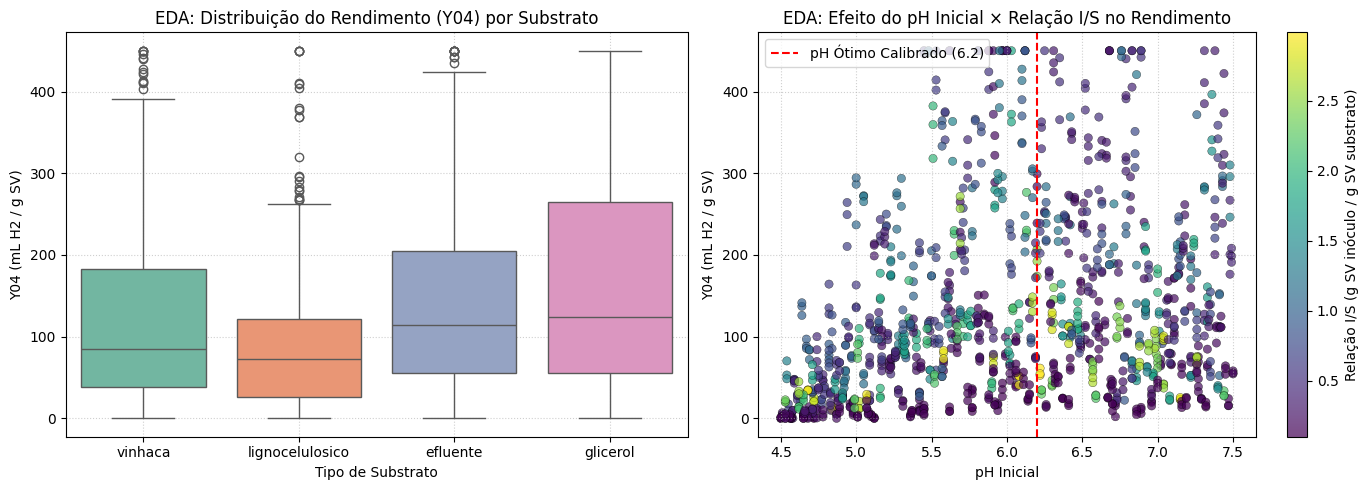

In [90]:
# BLOCO 9 (v0.2 - Pacote 3.1 da EAP): Gráficos de Análise Exploratória (EDA)
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Boxplot do Rendimento Y04 por Tipo de Substrato
sns.boxplot(
    data=df_v02,
    x='tipo_substrato',
    y='y04_ml_h2_por_g_sv',
    hue='tipo_substrato',
    palette='Set2',
    ax=ax1,
    legend=False
)
ax1.set_title('EDA: Distribuição do Rendimento (Y04) por Substrato')
ax1.set_xlabel('Tipo de Substrato')
ax1.set_ylabel('Y04 (mL H2 / g SV)')
ax1.grid(True, linestyle=':', alpha=0.6)

# Gráfico 2: Interação das 2 Variáveis Mais Importantes (pH Inicial vs Relação I/S)
dispersao = ax2.scatter(
    df_v02['ph_inicial'],
    df_v02['y04_ml_h2_por_g_sv'],
    c=df_v02['relacao_i_s'],
    cmap='viridis',
    alpha=0.7,
    edgecolors='k',
    linewidth=0.3
)
cbar = plt.colorbar(dispersao, ax=ax2)
cbar.set_label('Relação I/S (g SV inóculo / g SV substrato)')
ax2.axvline(6.2, color='red', linestyle='--', lw=1.5, label='pH Ótimo Calibrado (6.2)')
ax2.set_title('EDA: Efeito do pH Inicial × Relação I/S no Rendimento')
ax2.set_xlabel('pH Inicial')
ax2.set_ylabel('Y04 (mL H2 / g SV)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('eda_substrato_ph_v02.png', dpi=300)
plt.show()

10. O Efeito do Lote de Inóculo e do Gradient Boosting

In [91]:
# BLOCO 10 (Investigação Científica): O Efeito do Lote de Inóculo e do Gradient Boosting
from sklearn.ensemble import GradientBoostingRegressor

# 1. Testando o Gradient Boosting nas mesmas 7 variáveis atuais
pipeline_gb = Pipeline(steps=[
    ('preprocessamento', preprocessador),
    ('modelo_gb', GradientBoostingRegressor(n_estimators=200, learning_rate=0.08, max_depth=4, random_state=42))
])
pipeline_gb.fit(X_train, y_train)
y_pred_gb = pipeline_gb.predict(X_test)
r2_gb = r2_score(y_test, y_pred_gb)

# 2. E se incluirmos o 'lote_inoculo' (variação biológica entre coletas de lodo)?
col_cat_com_lote = colunas_categoricas + ['lote_inoculo']
X_lote = df_v02[col_cat_com_lote + colunas_numericas]
X_train_l, X_test_l = X_lote.iloc[idx_treino], X_lote.iloc[idx_teste]

prep_lote = ColumnTransformer(transformers=[
    ('num', regra_numerica, colunas_numericas),
    ('cat', regra_categorica, col_cat_com_lote)
])

pipe_com_lote = Pipeline(steps=[
    ('preprocessamento', prep_lote),
    ('modelo_gb', GradientBoostingRegressor(n_estimators=200, learning_rate=0.08, max_depth=4, random_state=42))
])
pipe_com_lote.fit(X_train_l, y_train)
y_pred_lote = pipe_com_lote.predict(X_test_l)
r2_com_lote = r2_score(y_test, y_pred_lote)

print("=== DESVENDANDO OS 36% DE VARIÂNCIA RESTANTES ===")
print(f"1. Random Forest (7 features sem lote):         R² = {r2:.4f} (MAE = {mae:.2f} mL/g SV)")
print(f"2. Gradient Boosting (7 features sem lote):     R² = {r2_gb:.4f} (MAE = {mean_absolute_error(y_test, y_pred_gb):.2f} mL/g SV)")
print(f"3. Gradient Boosting (+ 'lote_inoculo'):        R² = {r2_com_lote:.4f} (MAE = {mean_absolute_error(y_test, y_pred_lote):.2f} mL/g SV)")

=== DESVENDANDO OS 36% DE VARIÂNCIA RESTANTES ===
1. Random Forest (7 features sem lote):         R² = 0.6163 (MAE = 52.06 mL/g SV)
2. Gradient Boosting (7 features sem lote):     R² = 0.7350 (MAE = 42.40 mL/g SV)
3. Gradient Boosting (+ 'lote_inoculo'):        R² = 0.7219 (MAE = 42.98 mL/g SV)
